# Predicting heart disease using machine learning

This notebook looks into various python-based machine learning and data science libraries in an attempt to build a machine learning model capable of predicting whether or not someone has a heart disease based on their medical attributes

we are going to take the folowing approach:
1. Problem defintion
2. Data
3. Evaluation
4. Features
5. Modelling
6. Experimentation

##  1. Problem Definition

in a statement,
> Given clinical parameters about a patient, can we predict whether or not they have a heart disease?

##  2. Data

The original data came form cleaveland data from the UCI machine learing repository

## 3. Evaluation

> If we can reach 95% accuracy at predicting whether or not a patient has hear disease during the proof of concept, we will pursue the project

## 4. Features

This is where you will get different information about each of the feature in our dataset
> create data dictionary 

## Preparing the tools

we are going to use pandas, matplotlib and numpy for data analysis and manipulation

In [1]:
# Import all the tools we need

# Regular EDA and plotting libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Models from sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier


# Model Evaluation

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import RocCurveDisplay

## Load the data

In [2]:
df = pd.read_csv('heart-disease.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## Data exploration

Find out more about the data

1. what questions i am trying to solve?
2. what kind of data do we have and how do we treat types?
3. what is missing from the data and how do we deal with it?
4. where are the outliers and why should we care?
5. How can you add, change or remove features to get more out of our data?

In [3]:
df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


In [4]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [5]:
df['target'].value_counts()

target
1    165
0    138
Name: count, dtype: int64

In [6]:
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

<Axes: xlabel='target'>

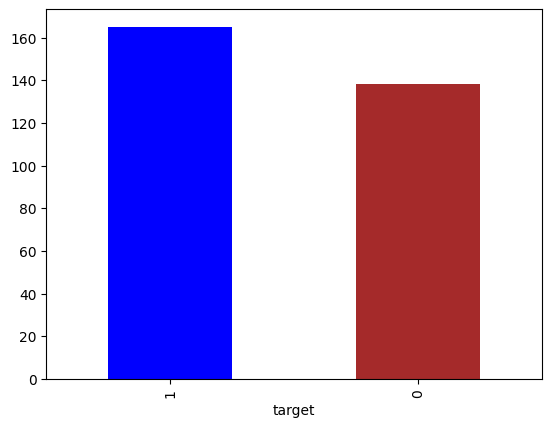

In [7]:
df['target'].value_counts().plot.bar(color = ['blue','brown'])

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


## Finding Patterns

### Heart disease frequency according to sex 

In [9]:
df.sex.value_counts()

sex
1    207
0     96
Name: count, dtype: int64

In [10]:
# Compare the sex and target columns

pd.crosstab(df.target,df.sex)

sex,0,1
target,,
0,24,114
1,72,93


(array([0, 1]), [Text(0, 0, '0'), Text(1, 0, '1')])

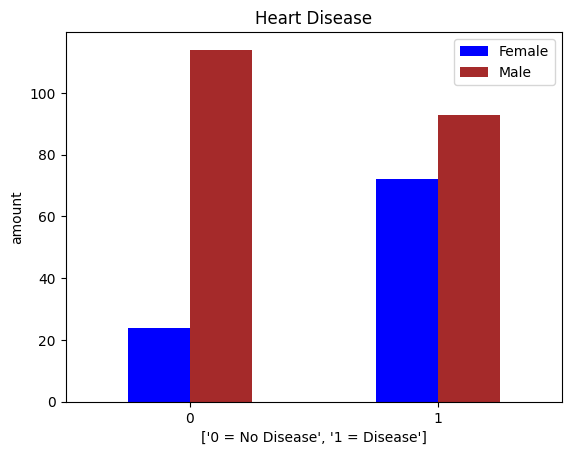

In [11]:
# Create a plot of crosstab
pd.crosstab(df.target,df.sex).plot.bar(color = ['blue','brown'])
plt.title('Heart Disease')
plt.xlabel(['0 = No Disease','1 = Disease'])
plt.ylabel('amount')
plt.legend(['Female','Male'])
plt.xticks(rotation = 0)

### compare age, thalach and target



Text(0.5, 1.0, 'Heart disease with age and max heart rate')

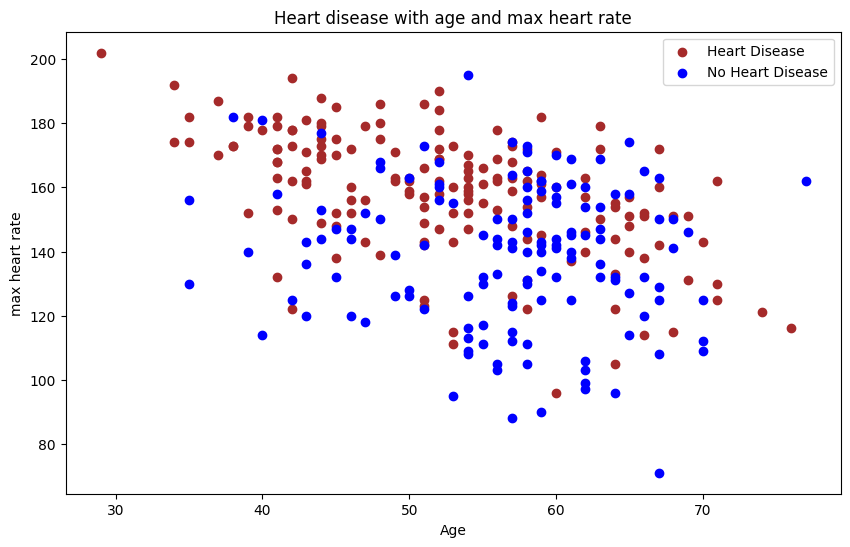

In [12]:
# Create another figure

plt.figure(figsize=(10,6))

# Scatter with positive examples
plt.scatter(df.age[df.target==1],df.thalach[df.target==1],c = 'brown');

# Scatetr with Negative examples
plt.scatter(df.age[df.target==0],df.thalach[df.target==0],c = 'blue');
plt.xlabel('Age')
plt.ylabel('max heart rate')
plt.legend(['Heart Disease','No Heart Disease'])
plt.title('Heart disease with age and max heart rate')

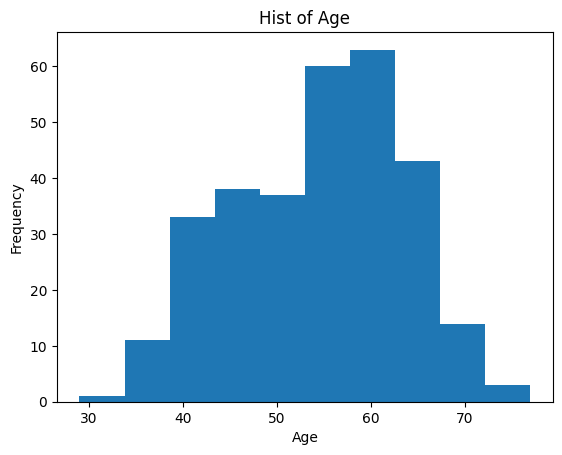

In [13]:
# Check the distribution of the age column with a histogram

df.age.plot.hist();
plt.xlabel('Age')
plt.title('Hist of Age');

### Heart disease frequency per Chest Pain Type

In [14]:
pd.crosstab(df.cp,df.target)

target,0,1
cp,,
0,104,39
1,9,41
2,18,69
3,7,16


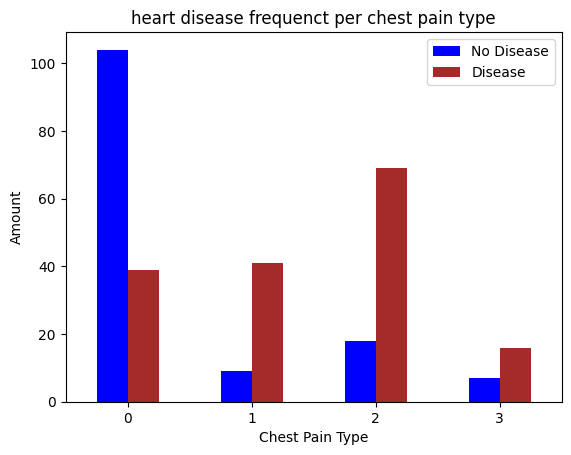

In [15]:
pd.crosstab(df.cp,df.target).plot.bar(color = ['blue','brown']);

plt.title("heart disease frequenct per chest pain type")
plt.xlabel('Chest Pain Type')
plt.ylabel('Amount')
plt.legend(['No Disease','Disease'])
plt.xticks(rotation = 0);

In [16]:
# building a correlation matrix

df.corr()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.098447,-0.068653,0.279351,0.213678,0.121308,-0.116211,-0.398522,0.096801,0.210013,-0.168814,0.276326,0.068001,-0.225439
sex,-0.098447,1.000000,-0.049353,-0.056769,-0.197912,0.045032,-0.058196,-0.044020,0.141664,0.096093,-0.030711,0.118261,0.210041,-0.280937
cp,-0.068653,-0.049353,1.000000,0.047608,-0.076904,0.094444,0.044421,0.295762,-0.394280,-0.149230,0.119717,-0.181053,-0.161736,0.433798
trestbps,0.279351,-0.056769,0.047608,1.000000,0.123174,0.177531,-0.114103,-0.046698,0.067616,0.193216,-0.121475,0.101389,0.062210,-0.144931
chol,0.213678,-0.197912,-0.076904,0.123174,1.000000,0.013294,-0.151040,-0.009940,0.067023,0.053952,-0.004038,0.070511,0.098803,-0.085239
fbs,0.121308,0.045032,0.094444,0.177531,0.013294,1.000000,-0.084189,-0.008567,0.025665,0.005747,-0.059894,0.137979,-0.032019,-0.028046
restecg,-0.116211,-0.058196,0.044421,-0.114103,-0.151040,-0.084189,1.000000,0.044123,-0.070733,-0.058770,0.093045,-0.072042,-0.011981,0.137230
thalach,-0.398522,-0.044020,0.295762,-0.046698,-0.009940,-0.008567,0.044123,1.000000,-0.378812,-0.344187,0.386784,-0.213177,-0.096439,0.421741
exang,0.096801,0.141664,-0.394280,0.067616,0.067023,0.025665,-0.070733,-0.378812,1.000000,0.288223,-0.257748,0.115739,0.206754,-0.436757
oldpeak,0.210013,0.096093,-0.149230,0.193216,0.053952,0.005747,-0.058770,-0.344187,0.288223,1.000000,-0.577537,0.222682,0.210244,-0.430696


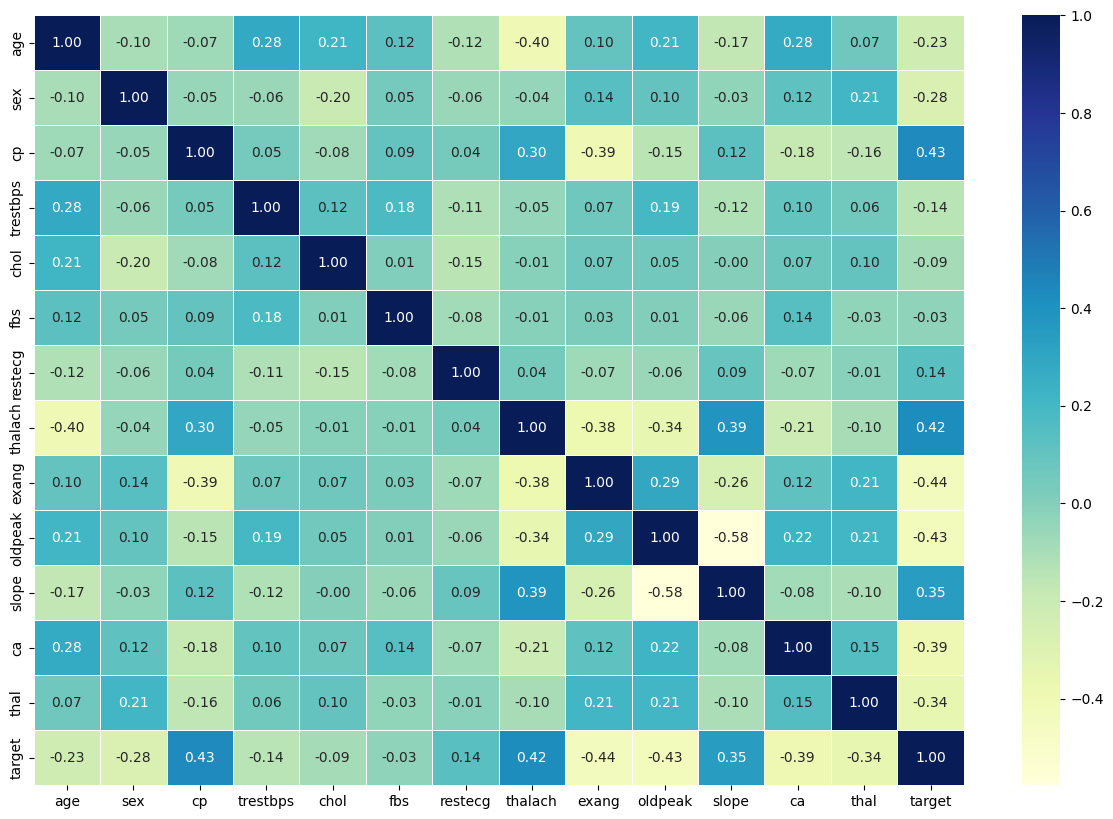

In [17]:
corr_matrix = df.corr()
fig, ax = plt.subplots(figsize = (15,10))
ax = sns.heatmap(corr_matrix,
                 annot= True,
                 linewidths=0.5,
                 fmt='.2f',
                 cmap='YlGnBu')

##  5. Modelling

In [18]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [19]:
# Split x and y
x = df.drop('target', axis = 1)
y = df['target']


# split into train and test
x_train,x_test, y_train, y_test = train_test_split(x,y,test_size=0.2)

In [20]:
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((242, 13), (61, 13), (242,), (61,))

In [21]:
models = {'Logistic Regression': LogisticRegression(),
          'KNN': KNeighborsClassifier(),
          'Random Forest Classifier': RandomForestClassifier()}
# results = {}


# Create a function to fit and score models
def fit_and_score(models,x_train,x_test,y_train,y_test):
    np.random.seed(42)
    model_score = {}
    # Loop through models
    for model_name,model in models.items():
        model.fit(x_train,y_train)
        model_score[model_name] = model.score(x_test,y_test)
    return model_score

In [22]:
model_score = fit_and_score(models=models,x_train=x_train,x_test=x_test,y_train=y_train,y_test=y_test)
model_score

c:\Users\bmmah\OneDrive\Documents\projects\learning udemy\Project 1 Classification\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'Logistic Regression': 0.819672131147541,
 'KNN': 0.5901639344262295,
 'Random Forest Classifier': 0.8032786885245902}

## Model comparison

<Axes: >

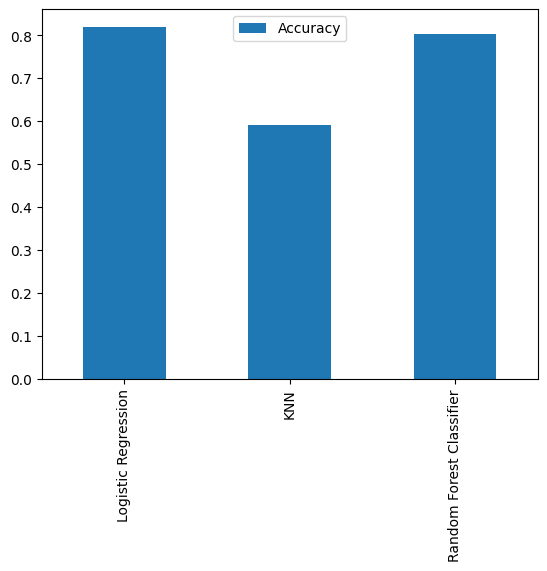

In [23]:
model_compare = pd.DataFrame(model_score,index = ['Accuracy'])
model_compare.T.plot.bar()

# Improving Hyperameter tuning

We have a baseline model and we know the models first prediction is not our model should be based on

we are going to be experimenting
 * Hyperparamter Tuning
 * Feature Importance
 * Confusion Matrix
 * Cross Validation
 * Precision
 * Recall
 * F1 Score
 * Classification Report
 * ROC Curve
 * Area Under Curve (AUC)

### Hyperparamter Tuning

In [24]:
# Let us Tune KNN

train_scores = []
test_scores = []

# Create a list of different values of n_neighbors
neighbors = range(1,21)

# Create a list of different values of n_neighbors
knn = KNeighborsClassifier()

# Loop through different n_neighbors
for i in neighbors:
    knn.set_params(n_neighbors = i)
    
    # Fit the algorithm
    knn.fit(x_train,y_train)
    
    # Update the training scores list
    train_scores.append(knn.score(x_train,y_train))
    
    # Update the test scores list
    test_scores.append(knn.score(x_test,y_test))

In [25]:
train_scores

[1.0,
 0.8057851239669421,
 0.7933884297520661,
 0.78099173553719,
 0.7768595041322314,
 0.768595041322314,
 0.768595041322314,
 0.7520661157024794,
 0.731404958677686,
 0.7107438016528925,
 0.7024793388429752,
 0.7107438016528925,
 0.7148760330578512,
 0.71900826446281,
 0.7024793388429752,
 0.7231404958677686,
 0.7272727272727273,
 0.71900826446281,
 0.7148760330578512,
 0.7148760330578512]

In [26]:
test_scores

[0.6229508196721312,
 0.6557377049180327,
 0.639344262295082,
 0.5901639344262295,
 0.5901639344262295,
 0.5901639344262295,
 0.6065573770491803,
 0.6229508196721312,
 0.5901639344262295,
 0.6557377049180327,
 0.7049180327868853,
 0.6721311475409836,
 0.639344262295082,
 0.6557377049180327,
 0.6229508196721312,
 0.6229508196721312,
 0.6229508196721312,
 0.6557377049180327,
 0.6557377049180327,
 0.6557377049180327]

Max KNN score on the test data: 70.49%


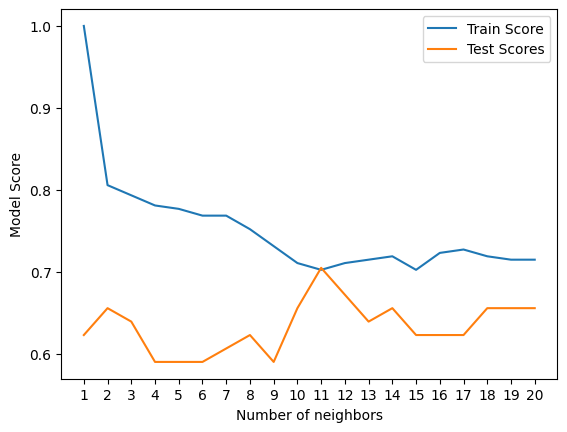

In [27]:
plt.plot(neighbors,train_scores, label = 'Train Score')
plt.plot(neighbors,test_scores,label = "Test Scores")
plt.xlabel('Number of neighbors')
plt.ylabel('Model Score')
plt.legend()
plt.xticks(np.arange(1,21,1))

print(f'Max KNN score on the test data: {max(test_scores)*100:.2f}%')

### Hyperparameter tuning with RandomizedSearchCV

we are going to tune:
    
    * LogisticRegression()
    * RandomForestClassifier()
using RandomizedSearchCV()

In [28]:
# Create a hyperparameter grid for Logistic regression
log_reg_grid = {'C':np.logspace(-4,4,20),
                'solver': ['liblinear']}

# Create hyperparmer grid for RandomForestClassifier
rf_grid = {'n_estimators': np.arange(10,1000,50),
           'max_depth':[None,3,5,10],
           'min_samples_split': np.arange(2,20,2),
           'min_samples_leaf': np.arange(1,20,2)}

Now we have hyperparameter grids for each of our models, let us tune them using RandomizedSearchCV..

In [29]:
# Tune LogisticRegression

np.random.seed(42)
# Setup random hyperparameters search for logisticregression
rs_log_reg = RandomizedSearchCV(LogisticRegression(),
                                param_distributions = log_reg_grid,
                                cv = 5,
                                n_iter = 20,
                                verbose = True)
# Fit random hyperparameters search model for LogisticRegression
rs_log_reg.fit(x_train,y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,estimator,LogisticRegression()
,param_distributions,"{'C': array([1.0000...00000000e+04]), 'solver': ['liblinear']}"
,n_iter,20
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,True
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [30]:
rs_log_reg.best_params_

{'solver': 'liblinear', 'C': np.float64(0.615848211066026)}

In [31]:
rs_log_reg.score(x_test,y_test)

0.8032786885245902

Now we have tuned LogisticRegression let us do the same for RandomForestClassifier

In [32]:
np.random.seed(42)

# Setup random hyperparameter search for RandomForestClassifier
rs_rf = RandomizedSearchCV(RandomForestClassifier(),
                           param_distributions=rf_grid,
                           cv = 5,
                           n_iter = 20,
                           verbose=True)
# Fit
rs_rf.fit(x_train,y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,estimator,RandomForestClassifier()
,param_distributions,"{'max_depth': [None, 3, ...], 'min_samples_leaf': array([ 1, 3..., 15, 17, 19]), 'min_samples_split': array([ 2, 4..., 14, 16, 18]), 'n_estimators': array([ 10, ...60, 910, 960])}"
,n_iter,20
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,True
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [33]:
rs_rf.best_params_

{'n_estimators': np.int64(210),
 'min_samples_split': np.int64(4),
 'min_samples_leaf': np.int64(19),
 'max_depth': 3}

In [34]:
rs_rf.score(x_test,y_test)

0.7868852459016393

In [35]:
model_score

{'Logistic Regression': 0.819672131147541,
 'KNN': 0.5901639344262295,
 'Random Forest Classifier': 0.8032786885245902}

## we are going to look at GridSearchCV

since our Logistic Regression has the best so we are going to look at it again

In [36]:
# Different hyperpamerter for the LogisticRegression
log_reg_grid = {'C':np.logspace(-4,4,30),
                'solver': ['liblinear']}

# Setup Grid Hyperparameter
gs_log_reg = GridSearchCV(LogisticRegression(),
                          param_grid = log_reg_grid,
                          cv = 5,
                          verbose = True)
# Fit
gs_log_reg.fit(x_train,y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,estimator,LogisticRegression()
,param_grid,"{'C': array([1.0000...00000000e+04]), 'solver': ['liblinear']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,True
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [37]:
gs_log_reg.best_params_

{'C': np.float64(0.7278953843983146), 'solver': 'liblinear'}

In [38]:
gs_log_reg.score(x_test,y_test)

0.8032786885245902

In [39]:
model_score

{'Logistic Regression': 0.819672131147541,
 'KNN': 0.5901639344262295,
 'Random Forest Classifier': 0.8032786885245902}

## Evaluating our tuned machine learing classfier, beyond accuracy

* ROC curve and AUC score 
* confusion_matrix
* classification_report
* precision_score
* recall_score
* f1_score

also cross_val_score 

To make comparisons and evaluate our trained model, we need to make predictions

In [40]:
# MAke predictions

y_pred = gs_log_reg.predict(x_test)

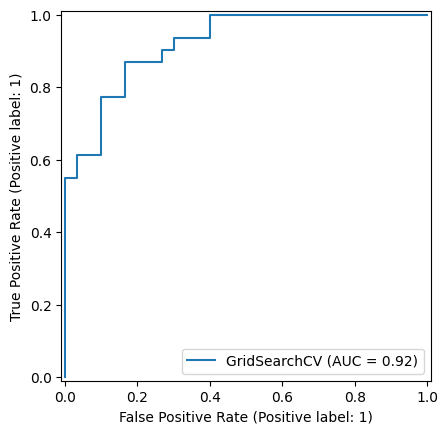

In [41]:
RocCurveDisplay.from_estimator(gs_log_reg,x_test,y_test)

In [42]:
# confusiion matrix
print(confusion_matrix(y_test,y_pred))

[[25  5]
 [ 7 24]]


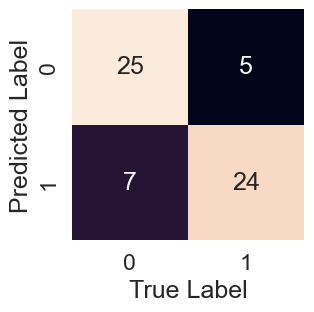

In [43]:
sns.set(font_scale = 1.5)

def plot_conf_mat(y_test,y_preds):
    fig, ax = plt.subplots(figsize =(3,3))
    ax = sns.heatmap(confusion_matrix(y_test,y_pred),
                     annot = True,
                     cbar = False)
    plt.xlabel('True Label')
    plt.ylabel('Predicted Label')
    
plot_conf_mat(y_test,y_pred)
    

we have got roc curve, auc score, and confusion matrix now we get classification_report

In [44]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.78      0.83      0.81        30
           1       0.83      0.77      0.80        31

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



### calculate evaluation using cross validation

we are going to calculate accuracy, recall, precision and f1 score

In [45]:
# Check the best parameter
gs_log_reg.best_params_

{'C': np.float64(0.7278953843983146), 'solver': 'liblinear'}

In [46]:
clf = LogisticRegression(C = 0.1082636733874054,
                         solver = 'liblinear')

In [47]:
# accuracy
cross_val = cross_val_score(clf,x,y,cv = 5, scoring = 'accuracy')
cross_val_accuracy = np.mean(cross_val)

In [48]:
# Precision
cross_val = cross_val_score(clf,x,y,cv = 5, scoring = 'precision')
cross_val_precision = np.mean(cross_val)

In [49]:
# recall
cross_val = cross_val_score(clf,x,y,cv = 5, scoring = 'recall')
cross_val_recall = np.mean(cross_val)

In [50]:
# f1
cross_val = cross_val_score(clf,x,y,cv = 5, scoring = 'f1')
cross_val_f1 = np.mean(cross_val)

<Axes: title={'center': 'Cross validated Metrics'}>

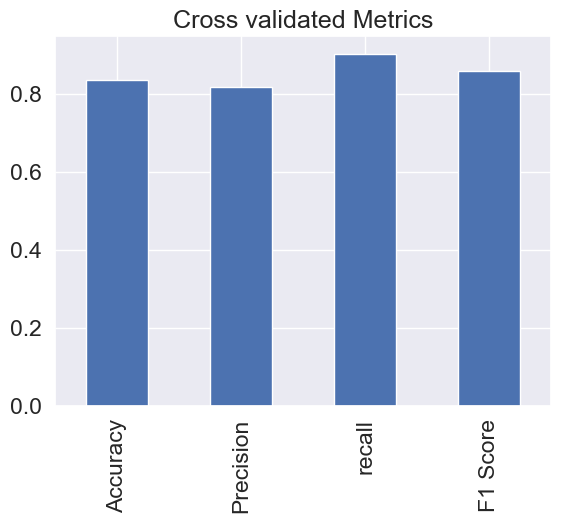

In [51]:
# Visualize the cross validate metrics
cv_metrics = pd.DataFrame({'Accuracy':cross_val_accuracy,
                           'Precision': cross_val_precision,
                           'recall': cross_val_recall,
                           'F1 Score':cross_val_f1},
                          index = [0])
cv_metrics.T.plot.bar(title = 'Cross validated Metrics', legend = False)

### Feature Importance
feature importance is how much each feature contributed to the outcomes of the model and how did they contribute?

Finding feature importance is different for each machine learning model.model_compare

Let's find the feature importance for our Logistic Regression model

In [53]:
# Fit an instance of the Logistic Regression
gs_log_reg.best_params_

clf = LogisticRegression(C = 0.7278953843983146,
                         solver = 'liblinear')
clf.fit(x_train,y_train);

In [55]:
# Check coef_
clf.coef_

array([[-2.82490283e-04, -1.41562103e+00,  8.30525115e-01,
        -1.39997945e-02, -2.14620146e-03,  1.59928304e-01,
         3.40959159e-01,  2.80436479e-02, -8.81434916e-01,
        -5.97674804e-01,  5.47839462e-01, -6.52885409e-01,
        -6.27807580e-01]])

In [56]:
# Match coef's features to columns
feature_dict = dict(zip(df.columns, list(clf.coef_[0])))
feature_dict

{'age': np.float64(-0.00028249028279416714),
 'sex': np.float64(-1.4156210330434646),
 'cp': np.float64(0.8305251146406853),
 'trestbps': np.float64(-0.013999794466067613),
 'chol': np.float64(-0.0021462014567398455),
 'fbs': np.float64(0.1599283041790256),
 'restecg': np.float64(0.3409591589801696),
 'thalach': np.float64(0.028043647897234028),
 'exang': np.float64(-0.8814349155562641),
 'oldpeak': np.float64(-0.5976748038880607),
 'slope': np.float64(0.547839462330355),
 'ca': np.float64(-0.652885408894203),
 'thal': np.float64(-0.627807579825417)}

<Axes: title={'center': 'Feature Importance'}>

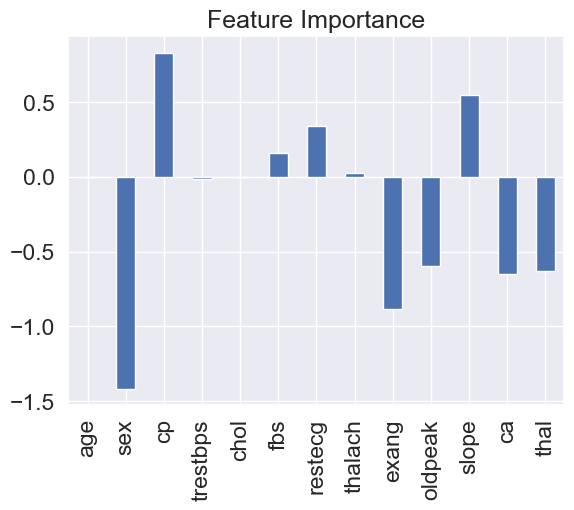

In [58]:
# Visualize feature importance
feature_df = pd.DataFrame(feature_dict,
                          index = [0])
feature_df.T.plot.bar(title = 'Feature Importance', legend = False)

In [60]:
pd.crosstab(df.sex,df.target)

target,0,1
sex,,
0,24,72
1,114,93


In [61]:
pd.crosstab(df.slope,df.target)

target,0,1
slope,,
0,12,9
1,91,49
2,35,107
